# Comparativa de detectores - vehículos y personas

En este cuaderno auxiliar se evalúan y comparan distintos modelos para la detección de personas y vehículos. Esto permite justificar la elección del detector utilizado en la primera parte de la práctica. En esta comparativa, se analizan las versiones **S** y **L** de cuatro familias de detectores (RT-DETRv4, YOLO26, DEIMv2 y ECDet) y la versión **X** de la familia YOLO, pues su eficiencia es tal que ofrece métricas de tiempo similares a las de versiones **L** de otros modelos.

## Evaluación

Todos los modelos se evalúan en las mismas condiciones:

- **Clases:** solo se buscan las clases correspondientes a personas (`person`) y vehículos (`car`, `motorcycle`, `bus`, `truck`). El resto de clases quedan descartadas. Además de las métricas de cada clase, se calculan las de `vehicle`, que agrupa los cuatro tipos de vehículo en una única clase.
- **Datos:** las 5,000 imágenes de COCO val2017, que ningún modelo ha visto durante su entrenamiento.
- **Métricas:** mAP@50-95 y mAP@50, además de _precision_, _recall_ y _accuracy_ con confianza ≥ 0.5 e IoU ≥ 0.5.
- **Tiempo:** inferencia completa por imagen (preprocesado, red y postprocesado), con _batch_ 1 y FP32, sin contar la lectura de disco.

Tras la evaluación de todos los modelos, se han agregado las estadísticas en tablas y en gráficas de TensorBoard.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Configuración](#11-configuración)
    - [1.2 Información del equipo](#12-información-del-equipo)
2. [Conjunto de datos](#2-conjunto-de-datos)
    - [2.1 Clases de COCO](#21-clases-de-coco)
    - [2.2 Anotaciones e imágenes](#22-anotaciones-e-imágenes)
3. [Métricas](#3-métricas)
    - [3.1 mAP](#31-map)
    - [3.2 _Precision_, _recall_ y _accuracy_](#32-precision-recall-y-accuracy)
4. [Detectores](#4-detectores)
    - [4.1 Repositorios y pesos](#41-repositorios-y-pesos)
    - [4.2 Detectores DETR](#42-detectores-detr)
    - [4.3 Detectores YOLO](#43-detectores-yolo)
5. [Evaluación de los modelos](#5-evaluación-de-los-modelos)
    - [5.1 Comprobación sobre una imagen](#51-comprobación-sobre-una-imagen)
    - [5.2 Generación de métricas](#52-generación-de-métricas)
    - [5.3 Resultados](#53-resultados)
    - [5.4 Diferencias entre L y S](#54-diferencias-entre-l-y-s)
6. [TensorBoard](#6-tensorboard)
7. [Conclusiones](#7-conclusiones)

## 1. Preparación

### 1.1 Configuración

In [1]:
import json
import math
import shutil
import urllib.request
import zipfile

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.tensorboard import SummaryWriter

from common.det_metrics import MAP_KEYS, PRF_KEYS, coco_map, get_metrics, timed_inference, to_coco_dets
from common.detectors import DetrDetector, YoloDetector
from common.detr import FAMILIES, coco_config, get_repo, get_weights
from common.paths import ROOT, RUNS, WEIGHTS
from common.specs import save_system_info

Rutas (las compartidas, en [`paths.py`](./common/paths.py)) donde se guardan los pesos descargados, las imágenes y anotaciones de COCO, los resultados de cada modelo y los registros de TensorBoard:

In [2]:
DATA = ROOT / "coco"
IMG_DIR = DATA / "val2017"
ANNOTATIONS_JSON = DATA / "instances_val2017_classes.json"
VEHICLE_ANNOTATIONS_JSON = DATA / "instances_val2017_vehicle.json"
RESULTS = ROOT / "results"
TENSORBOARD = RUNS / "modelos"

for d in (WEIGHTS, DATA, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

Parámetros de la comparativa:

- `WARMUP`: imágenes de calentamiento, que se procesan antes de empezar a medir el tiempo, para evitar sesgar las estadísticas con un arranque en frío.
- `TOP_K`: número máximo de detecciones por imagen.
- `SCORE_MIN`: confianza mínima de las detecciones que se usan para calcular el mAP.
- `CONF_PRF` e `IOU_PRF`: umbrales de confianza e IoU para calcular _precision_, _recall_ y _accuracy_.

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WARMUP = 10
TOP_K = 300
SCORE_MIN = 0.001
CONF_PRF = 0.5
IOU_PRF = 0.5

print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU)")

device: cuda NVIDIA GeForce RTX 5080


### 1.2 Información del equipo

Los tiempos dependen del equipo en el que se miden, por lo que se guarda esta información en `system_info.json` (ver funciones en [`specs.py`](./common/specs.py)):

In [4]:
PACKAGES = ["torch", "torchvision", "ultralytics", "faster-coco-eval", "opencv-python", "numpy", "pandas"]

save_system_info(RESULTS / "system_info.json", PACKAGES)

{'os': 'Windows-10-10.0.26200-SP0',
 'cpu': 'AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD',
 'cpu_cores': 8,
 'ram_gb': 34.0,
 'python': '3.11.18',
 'gpu': 'NVIDIA GeForce RTX 5080',
 'gpu_driver': '610.88',
 'cuda': '13.0',
 'packages': {'torch': '2.14.1+cu130',
  'torchvision': '0.29.1+cu130',
  'ultralytics': '8.4.202',
  'faster-coco-eval': '1.8.0',
  'opencv-python': '5.0.0.93',
  'numpy': '2.3.5',
  'pandas': '3.1.1'}}

## 2. Conjunto de datos

### 2.1 Clases de COCO

Los modelos y las anotaciones de COCO no identifican las clases de la misma forma:

- Los modelos devuelven la **posición** de la clase dentro de la lista de 80 clases de COCO (de 0 a 79).
- Las anotaciones utilizan el `category_id` de cada clase, que no sigue el orden secuencial.

Por ejemplo, `car` es la clase 2 para los modelos, pero su `category_id` es 3. Para poder comparar las detecciones con las anotaciones, se guarda la lista de clases con su `category_id`, en el mismo orden en que las devuelven los modelos. Así, `LABEL_TO_CAT[i]` es el `category_id` de la clase `i`:

In [5]:
COCO_CATEGORIES = [
    (1, "person"), (2, "bicycle"), (3, "car"), (4, "motorcycle"), (5, "airplane"), (6, "bus"), (7, "train"),
    (8, "truck"), (9, "boat"), (10, "traffic light"), (11, "fire hydrant"), (13, "stop sign"),
    (14, "parking meter"), (15, "bench"), (16, "bird"), (17, "cat"), (18, "dog"), (19, "horse"), (20, "sheep"),
    (21, "cow"), (22, "elephant"), (23, "bear"), (24, "zebra"), (25, "giraffe"), (27, "backpack"),
    (28, "umbrella"), (31, "handbag"), (32, "tie"), (33, "suitcase"), (34, "frisbee"), (35, "skis"),
    (36, "snowboard"), (37, "sports ball"), (38, "kite"), (39, "baseball bat"), (40, "baseball glove"),
    (41, "skateboard"), (42, "surfboard"), (43, "tennis racket"), (44, "bottle"), (46, "wine glass"),
    (47, "cup"), (48, "fork"), (49, "knife"), (50, "spoon"), (51, "bowl"), (52, "banana"), (53, "apple"),
    (54, "sandwich"), (55, "orange"), (56, "broccoli"), (57, "carrot"), (58, "hot dog"), (59, "pizza"),
    (60, "donut"), (61, "cake"), (62, "chair"), (63, "couch"), (64, "potted plant"), (65, "bed"),
    (67, "dining table"), (70, "toilet"), (72, "tv"), (73, "laptop"), (74, "mouse"), (75, "remote"),
    (76, "keyboard"), (77, "cell phone"), (78, "microwave"), (79, "oven"), (80, "toaster"), (81, "sink"),
    (82, "refrigerator"), (84, "book"), (85, "clock"), (86, "vase"), (87, "scissors"), (88, "teddy bear"),
    (89, "hair drier"), (90, "toothbrush"),
]

CAT2NAME = dict(COCO_CATEGORIES)
LABEL_TO_CAT = np.array([cat for cat, _ in COCO_CATEGORIES])

De todas ellas, solo interesan `person` (0), `car` (2), `motorcycle` (3), `bus` (5) y `truck` (7). La función `labels_to_cats` realiza la traducción de clase de modelo a `category_id`:

In [6]:
KEEP_LABELS = [0, 2, 3, 5, 7]
CLASSES = {int(LABEL_TO_CAT[i]): CAT2NAME[int(LABEL_TO_CAT[i])] for i in KEEP_LABELS}

def labels_to_cats(labels):
    return LABEL_TO_CAT[np.asarray(labels).astype(int)]

print(CLASSES)

{1: 'person', 3: 'car', 4: 'motorcycle', 6: 'bus', 8: 'truck'}


Para medir la detección de vehículos sin importar su tipo, se agrupan `car`, `motorcycle`, `bus` y `truck` en una nueva clase `vehicle`, con un `category_id` que no existe en COCO. De esta forma, un camión detectado como coche cuenta como acierto en `vehicle`, aunque sea un fallo en `car` y en `truck`:

In [7]:
VEHICLE_ID = 100
VEHICLE_CATS = [cat for cat, name in CLASSES.items() if name != "person"]
VEHICLE = {VEHICLE_ID: "vehicle"}

REPORT_CLASSES = [*CLASSES.values(), "vehicle"]
PLOT_CLASSES = ["person", "car", "vehicle"]

### 2.2 Anotaciones e imágenes

Se utilizan las imágenes de COCO val2017. Siguiendo el estándar de COCO, se incluyen también las imágenes sin personas ni vehículos, en las que cualquier detección es un falso positivo.

En primer lugar, se descargan las anotaciones del dataset:

In [8]:
def load_val2017_annotations():
    json_path = DATA / "annotations" / "instances_val2017.json"
    zip_path = DATA / "annotations_trainval2017.zip"

    if not json_path.exists():
        urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extract("annotations/instances_val2017.json", DATA)

    return json.load(open(json_path, encoding="utf-8"))

A continuación, se guardan dos ficheros de anotaciones con todas las imágenes:

- `ANNOTATIONS_JSON`: solo las anotaciones de las cinco clases de personas y vehículos.
- `VEHICLE_ANNOTATIONS_JSON`: solo las anotaciones de vehículos, con su `category_id` cambiado por `VEHICLE_ID`.

In [9]:
def save_annotations(coco, annotations, categories, path):
    data = {"info": coco.get("info", {}), "licenses": coco.get("licenses", []),
            "images": coco["images"], "annotations": annotations, "categories": categories}
    json.dump(data, open(path, "w"))


def build_annotations():
    coco = load_val2017_annotations()
    save_annotations(coco,
                     [a for a in coco["annotations"] if a["category_id"] in CLASSES],
                     [c for c in coco["categories"] if c["id"] in CLASSES],
                     ANNOTATIONS_JSON)
    save_annotations(coco,
                     [{**a, "category_id": VEHICLE_ID} for a in coco["annotations"] if a["category_id"] in VEHICLE_CATS],
                     [{"id": VEHICLE_ID, "name": "vehicle", "supercategory": "vehicle"}],
                     VEHICLE_ANNOTATIONS_JSON)

Por último, se descargan y se extraen las imágenes del conjunto de datos:

In [10]:
def download_images():
    zip_path = DATA / "val2017.zip"

    if not IMG_DIR.exists():
        print("Descargando imágenes de val2017...")
        urllib.request.urlretrieve("http://images.cocodataset.org/zips/val2017.zip", zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(DATA)


def read_image(im):
    return cv2.imread(str(IMG_DIR / im["file_name"]))

In [11]:
if not ANNOTATIONS_JSON.exists() or not VEHICLE_ANNOTATIONS_JSON.exists():
    build_annotations()
download_images()

val2017 = json.load(open(ANNOTATIONS_JSON, encoding="utf-8"))
IMAGES = sorted(val2017["images"], key=lambda im: im["id"])

Número de imágenes en las que aparece cada clase y número total de objetos (instancias) de cada una:

In [12]:
def count_class(annotations, cats):
    found = [a for a in annotations if a["category_id"] in cats]
    n_images = len({a["image_id"] for a in found})
    return n_images, len(found)


groups = {name: [cat] for cat, name in CLASSES.items()}
groups["vehicle"] = VEHICLE_CATS

for name, cats in groups.items():
    n_images, n_instances = count_class(val2017["annotations"], cats)
    print(f"{name}: {n_images} imágenes, {n_instances} instancias")
print(f"Total: {len(IMAGES)} imágenes")

person: 2693 imágenes, 11004 instancias
car: 535 imágenes, 1932 instancias
motorcycle: 159 imágenes, 371 instancias
bus: 189 imágenes, 285 instancias
truck: 250 imágenes, 415 instancias
vehicle: 796 imágenes, 3003 instancias
Total: 5000 imágenes


## 3. Métricas

Las métricas están en [`det_metrics.py`](./common/det_metrics.py), compartidas con la comparativa de matrículas.

### 3.1 mAP

`coco_map` calcula el mAP@50-95 y el mAP@50 con `faster_coco_eval`, tanto en total (sobre las cinco clases) como individualmente para cada clase (`class_map`).

### 3.2 _Precision_, _recall_ y _accuracy_

Para realizar el _matching_ de las detecciones se utiliza el IoU (`iou`), que permite diferenciar entre verdaderos positivos, falsos positivos y falsos negativos en cada imagen (`match_image`). A partir de estos emparejamientos, `get_metrics` calcula las tres métricas (_precision_, _recall_ y _accuracy_), en total y para cada clase.

Para evaluar la clase `vehicle`, todas las detecciones y anotaciones de vehículos pasan a tener la misma clase, `VEHICLE_ID`. Se gestionan las detecciones duplicadas siguiendo el estándar (mayor confianza = TP, resto de detecciones = FP):

In [17]:
def to_vehicle(dets):
    return [{**d, "category_id": VEHICLE_ID} for d in dets if d["category_id"] in VEHICLE_CATS]


def compute_metrics(dets):
    map_res = coco_map(ANNOTATIONS_JSON, dets, CLASSES)
    prf_res = get_metrics(ANNOTATIONS_JSON, dets, CLASSES, CONF_PRF, IOU_PRF)

    vehicle_dets = to_vehicle(dets)
    map_res["vehicle"] = coco_map(VEHICLE_ANNOTATIONS_JSON, vehicle_dets, VEHICLE)["vehicle"]
    prf_res["vehicle"] = get_metrics(VEHICLE_ANNOTATIONS_JSON, vehicle_dets, VEHICLE, CONF_PRF, IOU_PRF)["vehicle"]
    return map_res, prf_res

## 4. Detectores

Todos los detectores reciben una imagen BGR, devuelven el mismo resultado (cajas, confianzas y clases) y deben liberar la memoria de la GPU al terminar. Por eso, se unifican las funcionalidades comunes en la clase `Detector` ([`detectors.py`](./common/detectors.py)).

Cada modelo se identifica como `<familia>-<tamaño>` (por ejemplo, `rtdetrv4-l`). A partir de ese nombre, `load_detector` crea el detector de la familia correspondiente ([DETR](#42-detectores-detr) o [YOLO](#43-detectores-yolo)), y `prefetch` descarga el repositorio y los pesos que necesita:

In [19]:
def split_name(name):
    return name.rsplit("-", 1)


def load_detector(name, keep=KEEP_LABELS):
    family, size = split_name(name)
    if family == "yolo26":
        return YoloDetector(name, WEIGHTS / f"yolo26{size}.pt", keep, score_min=SCORE_MIN, top_k=TOP_K)
    if family in FAMILIES:
        return DetrDetector(name, family, coco_config(family, size), get_weights(family, size), DEVICE, keep, TOP_K)
    raise ValueError(f"Familia desconocida: {name}")


def prefetch(name):
    family, size = split_name(name)
    if family in FAMILIES:
        get_repo(family)
        get_weights(family, size)

### 4.1 Repositorios y pesos

YOLO26 se carga con Ultralytics, que descarga los pesos automáticamente. Sin embargo, el resto de los modelos se deben cargar junto a sus pesos desde su repositorio oficial. De esto se encarga [`detr.py`](./common/detr.py):

- `FAMILIES`: agrupa el repositorio, la configuración y los pesos de COCO de cada familia.
- `get_repo` y `get_weights`: descargan el repositorio y los pesos oficiales, en caso de no estar ya descargados en el equipo (los ficheros de Google Drive podrían dar problemas).
- `use_repo_engine`: los tres repositorios tienen un paquete llamado `engine`, lo que provoca conflictos al importar los distintos modelos. Para evitarlo, en cada cambio de familia se eliminan los módulos de `engine` ya importados y se deja en el _path_ únicamente el repositorio de la familia actual.

### 4.2 Detectores DETR

Los modelos DETR (RT-DETRv4, DEIMv2 y ECDet) se cargan desde su repositorio oficial, que solo proporciona la red. Es por esto que el preprocesado de la imagen y el postprocesado de las salidas se implementan manualmente en `DetrDetector` ([`detectors.py`](./common/detectors.py)), con ayuda de las funciones de [`detr.py`](./common/detr.py):

1. **Construcción del modelo** (`build_model`). Los repositorios no ofrecen una función que cargue directamente un modelo entrenado, sino que lo construyen a partir de un fichero de configuración YAML:
    1. `load_config` carga la configuración. Como está pensada para entrenar, el _backbone_ intenta cargar sus pesos preentrenados. Como se tienen que cargar los pesos específicos de COCO, se desactiva este comportamiento con `INFERENCE_OVERRIDES`.
    2. `load_ema_weights` carga los pesos de COCO, usando su versión EMA si está disponible, pues suele dar mejores resultados.
    3. `move_pos_embeds` mueve los _position embeddings_ a la GPU, pues por defecto RT-DETRv4 los mantiene en la CPU como atributos normales.
2. **Preprocesado** (`preprocess`): conversión de la imagen a RGB, reescalado a la resolución de entrada del modelo y, si el modelo lo requiere, normalización con la media y la desviación de ImageNet (`imagenet_norm`).
3. **Postprocesado**: el `PostProcessor` oficial escoge las 300 mejores detecciones entre todas las combinaciones de _queries_ y clases. Como solo utilizamos 5 clases de las 80 existentes, y para mantener coherencia con el `classes=KEEP_LABELS` de YOLO, se descartan las clases no utilizadas antes de escoger las _top-k_ detecciones, para tener 300 detecciones de personas y vehículos. Sus cajas se pasan a píxeles con `boxes_to_pixels`.

### 4.3 Detectores YOLO

Por otro lado, YOLO26 se ejecuta directamente desde la librería de _Ultralytics_ (`YoloDetector`), y ya incluye el preprocesado y el postprocesado. Solo es necesario restringir la búsqueda a las 5 clases deseadas (`classes=keep`).

## 5. Evaluación de los modelos

Se evalúan los distintos modelos (`MODELS`), que se deben descargar antes. Si un modelo ya se ha medido, se reutilizan sus resultados, a no ser que se indique `FORCE = True`:

In [32]:
MODELS = ["rtdetrv4-l", "yolo26-l", "deimv2-l", "ec-l", "rtdetrv4-s", "yolo26-s", "deimv2-s", "ec-s", "yolo26-x"]
FORCE = False

for name in MODELS:
    prefetch(name)

### 5.1 Comprobación sobre una imagen

Antes de realizar la comparativa, se analizan las diferencias visualmente, observando las detecciones de cada modelo sobre la imagen de _test_ proporcionada en el README de la práctica:

W1108 09:53:24.987000 3464 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Training DINOv3 from scratch...
Using Lite Spatial Prior Module with inplanes=32
     --- Use Gateway@True ---
     --- Use Share Bbox Head@False ---
     --- Use Share Score Head@False ---
     --- Wide Layer@1 ---


Training ViT-Tiny from scratch...
Using Lite Spatial Prior Module with inplanes=16
     --- Use Gateway@True ---
     --- Use Share Bbox Head@False ---
     --- Use Share Score Head@False ---
     --- Wide Layer@1 ---


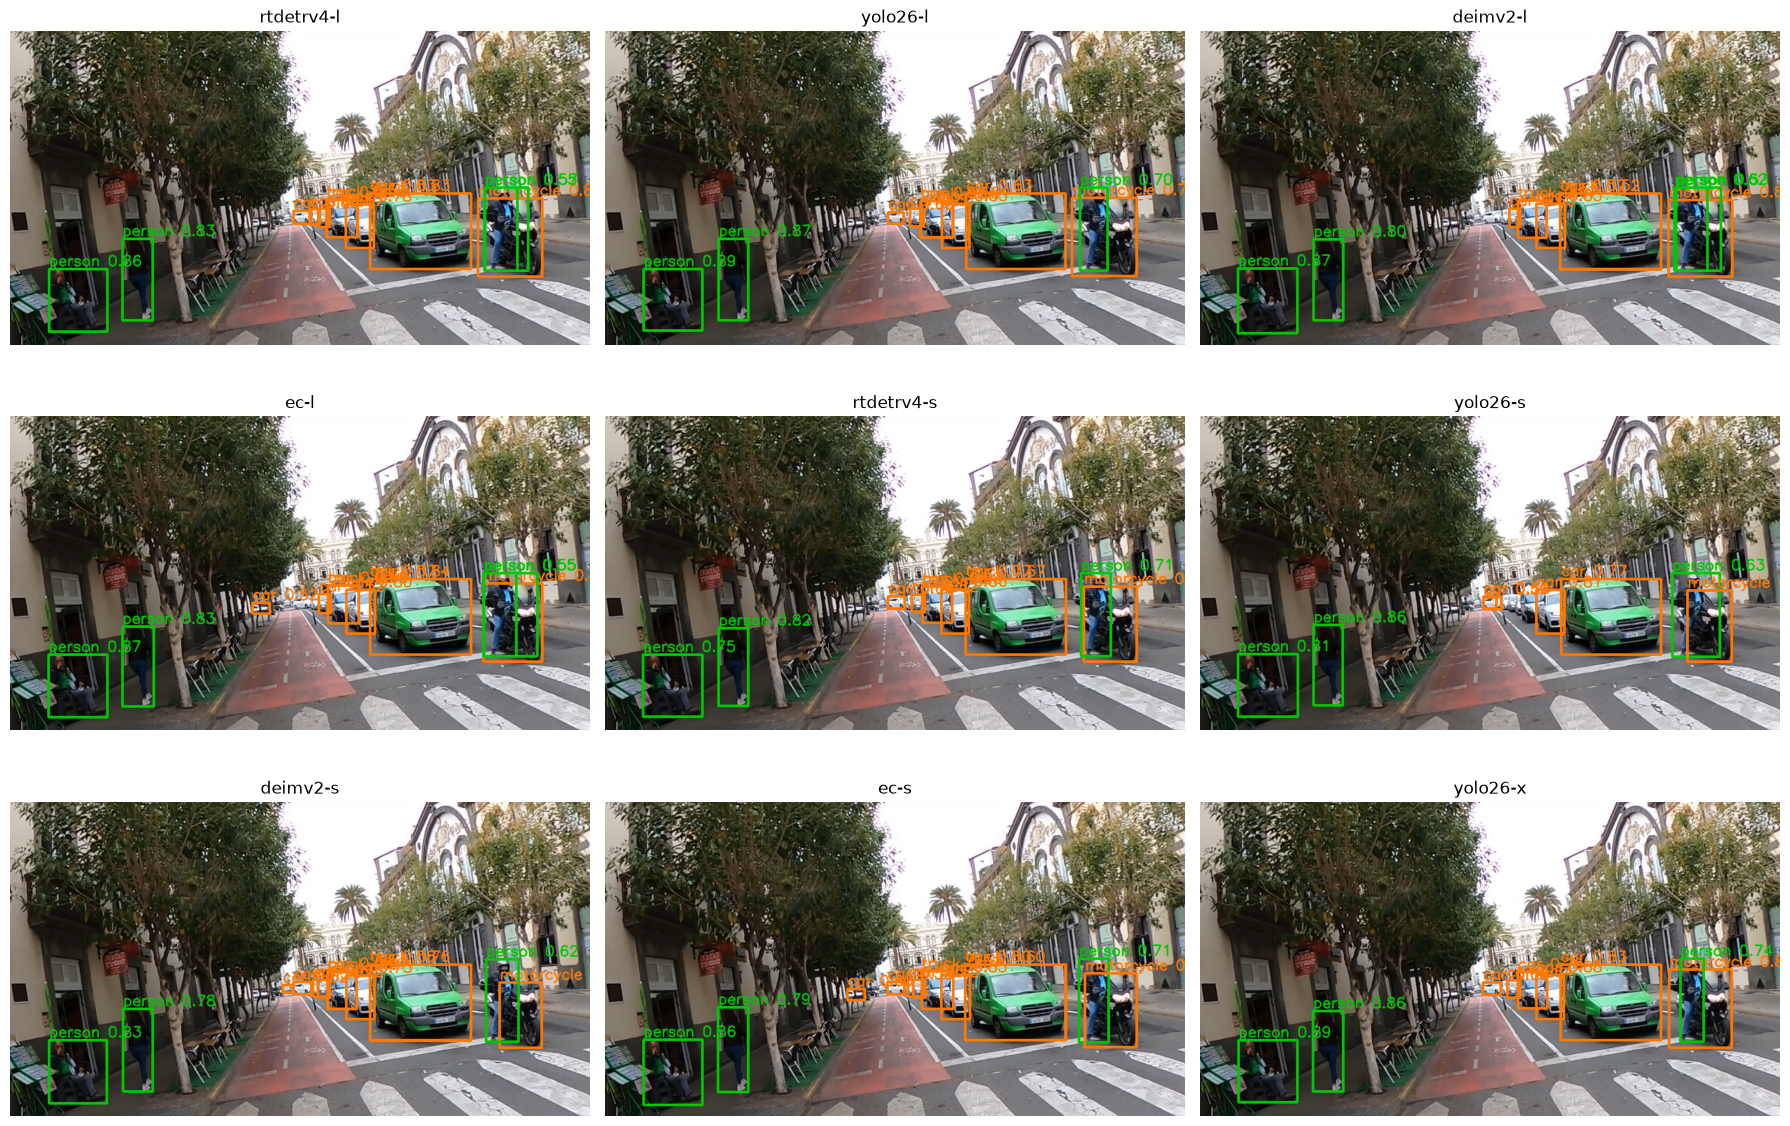

In [33]:
def draw_detections(image, det, min_score=0.5):
    out = image.copy()
    boxes, scores, labels = det(image)
    for box, score, cat in zip(boxes, scores, labels_to_cats(labels)):
        if score < min_score:
            continue
        x1, y1, x2, y2 = box.astype(int)
        color = (0, 200, 0) if CLASSES[cat] == "person" else (0, 120, 255)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 3)
        cv2.putText(out, f"{CLASSES[cat]} {score:.2f}", (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)


img = cv2.imread(str(ROOT / "test.jpg"))
n_cols = 3
n_rows = math.ceil(len(MODELS) / n_cols)

plt.figure(figsize=(6 * n_cols, 4 * n_rows))
for i, name in enumerate(MODELS):
    det = load_detector(name)
    plt.subplot(n_rows, n_cols, i + 1)
    plt.imshow(draw_detections(img, det))
    plt.title(name)
    plt.axis("off")
    det.close()
plt.tight_layout()
plt.show()

### 5.2 Generación de métricas

Para cada modelo, `timed_inference` ([`det_metrics.py`](./common/det_metrics.py)) primero procesa algunas imágenes sin medir el tiempo (calentamiento). A continuación, recorre todo el _dataset_ midiendo únicamente la ejecución del detector. Se debe llamar a `cuda.synchronize()` porque la GPU trabaja de forma asíncrona.

Con los tiempos y las métricas de cada modelo, se construye la tabla de resultados:

1. `build_row`: junta los tiempos y las métricas de un modelo en una fila.
2. `evaluate`: mide el modelo con `timed_inference`, pasa sus detecciones al formato de COCO (`to_coco_dets`) y calcula sus métricas.
3. `load_or_measure`: guarda las predicciones y la fila de cada modelo en `results/`, y las reutiliza si ya existen.

In [35]:
def build_row(name, n_params, total_s, n_images, map_res, prf_res):
    family, size = split_name(name)
    row = {"model": name, "family": family, "size": size.upper(), "params_M": n_params / 1e6,
           "n_images": n_images, "total_s": total_s, "ms_per_img": 1000 * total_s / n_images,
           "fps": n_images / total_s}
    row.update({k: map_res[k] for k in MAP_KEYS})
    row.update({k: prf_res[k] for k in (*PRF_KEYS, "TP", "FP", "FN")})
    for c in REPORT_CLASSES:
        row.update({f"{k}_{c}": map_res[c][k] for k in MAP_KEYS})
        row.update({f"{k}_{c}": prf_res[c][k] for k in PRF_KEYS})
    return row

In [36]:
def evaluate(name, images):
    det = load_detector(name)
    try:
        outputs, total_s = timed_inference(det, images, read_image, WARMUP)
        n_params = det.n_params
    finally:
        det.close()
    dets = [d for im, (boxes, scores, labels) in zip(images, outputs)
            for d in to_coco_dets(im["id"], boxes, scores, labels_to_cats(labels), SCORE_MIN)]
    json.dump(dets, open(RESULTS / f"preds_{name}.json", "w"))
    return build_row(name, n_params, total_s, len(images), *compute_metrics(dets))

def load_or_measure(name, images, force=False):
    path = RESULTS / f"metrics_{name}.json"
    if path.exists() and not force:
        return json.load(open(path))
    print(f"Midiendo {name}...", flush=True)
    row = evaluate(name, images)
    json.dump(row, open(path, "w"), indent=1)
    return row

def print_row(row):
    print(f"{row['model']:11s} mAP50-95={row['mAP50-95']:.3f}  P={row['precision']:.3f}  R={row['recall']:.3f}  "
          f"acc={row['accuracy']:.3f}  tiempo={row['total_s']:.1f}s ({row['ms_per_img']:.1f} ms/img)", flush=True)

### 5.3 Resultados

Resultados de todos los modelos, que se juntan en `results.csv`:

In [37]:
rows = []
for name in MODELS:
    row = load_or_measure(name, IMAGES, FORCE)
    rows.append(row)
    print_row(row)

df = pd.DataFrame(rows)
df.to_csv(RESULTS / "results.csv", index=False)
df[["model", "params_M", "total_s", "ms_per_img", "fps", "mAP50-95", "mAP50", "precision", "recall", "accuracy"]].round(3)

rtdetrv4-l  mAP50-95=0.603  P=0.847  R=0.725  acc=0.641  tiempo=91.6s (18.3 ms/img)


yolo26-l    mAP50-95=0.588  P=0.911  R=0.633  acc=0.597  tiempo=55.5s (11.1 ms/img)


deimv2-l    mAP50-95=0.606  P=0.847  R=0.712  acc=0.631  tiempo=90.5s (18.1 ms/img)


ec-l        mAP50-95=0.612  P=0.847  R=0.723  acc=0.640  tiempo=83.6s (16.7 ms/img)


rtdetrv4-s  mAP50-95=0.551  P=0.846  R=0.670  acc=0.597  tiempo=53.4s (10.7 ms/img)


yolo26-s    mAP50-95=0.531  P=0.917  R=0.581  acc=0.552  tiempo=36.5s (7.3 ms/img)


deimv2-s    mAP50-95=0.558  P=0.843  R=0.675  acc=0.600  tiempo=67.3s (13.5 ms/img)


ec-s        mAP50-95=0.569  P=0.854  R=0.687  acc=0.615  tiempo=62.7s (12.5 ms/img)


yolo26-x    mAP50-95=0.603  P=0.908  R=0.660  acc=0.619  tiempo=63.2s (12.6 ms/img)


,model,params_M,total_s,ms_per_img,fps,mAP50-95,mAP50,precision,recall,accuracy
0,rtdetrv4-l,30.967,91.644,18.329,54.559,0.603,0.803,0.847,0.725,0.641
1,yolo26-l,26.300,55.513,11.103,90.069,0.588,0.773,0.911,0.633,0.597
2,deimv2-l,32.178,90.493,18.099,55.253,0.606,0.801,0.847,0.712,0.631
3,ec-l,32.665,83.599,16.720,59.809,0.612,0.812,0.847,0.723,0.640
4,rtdetrv4-s,10.435,53.426,10.685,93.587,0.551,0.749,0.846,0.670,0.597
5,yolo26-s,10.010,36.534,7.307,136.858,0.531,0.721,0.917,0.581,0.552
6,deimv2-s,9.707,67.317,13.463,74.275,0.558,0.763,0.843,0.675,0.600
7,ec-s,9.811,62.653,12.531,79.804,0.569,0.778,0.854,0.687,0.615
8,yolo26-x,58.993,63.220,12.644,79.089,0.603,0.784,0.908,0.660,0.619


### 5.4 Diferencias entre L y S

Para cada familia y cada métrica, se calcula la mejora que presenta el modelo L frente al S:

In [38]:
t = df.set_index(["family", "size"])

comparison = []
for fam in dict.fromkeys(df.family):
    S, L = t.loc[(fam, "S")], t.loc[(fam, "L")]
    comparison.append({
        "familia": fam,
        "params_S": S.params_M,
        "params_L": L.params_M,
        "mAP50-95 (pts)": 100 * (L["mAP50-95"] - S["mAP50-95"]),
        "mAP50 (pts)": 100 * (L["mAP50"] - S["mAP50"]),
        "precision (pts)": 100 * (L.precision - S.precision),
        "recall (pts)": 100 * (L.recall - S.recall),
        "accuracy (pts)": 100 * (L.accuracy - S.accuracy),
        "t_S": S.total_s,
        "t_L": L.total_s,
    })

comparison = pd.DataFrame(comparison).round(2)
comparison.to_csv(RESULTS / "comparativa_L_vs_S.csv", index=False)
comparison

,familia,params_S,params_L,mAP50-95 (pts),mAP50 (pts),precision (pts),recall (pts),accuracy (pts),t_S,t_L
0,rtdetrv4,10.43,30.97,5.26,5.43,0.17,5.51,4.43,53.43,91.64
1,yolo26,10.01,26.30,5.74,5.25,-0.53,5.25,4.49,36.53,55.51
2,deimv2,9.71,32.18,4.81,3.80,0.34,3.72,3.11,67.32,90.49
3,ec,9.81,32.66,4.26,3.35,-0.63,3.60,2.51,62.65,83.60


## 6. TensorBoard

Se registra en TensorBoard un _run_ por modelo (`runs/modelos/<familia>-<tamaño>`), con un único punto situado en su tiempo total en ms (eje _Step_). Además, en la pestaña HPARAMS se muestra una tabla con todos los modelos:

In [39]:
METRICS = ("mAP50-95", "mAP50", "precision", "recall", "accuracy")
CLASS_METRICS = ("mAP50-95", "precision", "recall", "accuracy")


def log_metrics(w, row, step):
    for k in METRICS:
        w.add_scalar(k, 100 * row[k], step)
    for c in PLOT_CLASSES:
        for k in CLASS_METRICS:
            w.add_scalar(f"{k}/{c}", 100 * row[f"{k}_{c}"], step)
    w.add_scalar("ms_por_imagen", row["ms_per_img"], step)


def log_hparams(w, row):
    hparams = {"familia": row["family"], "tamaño": row["size"], "params_M": round(row["params_M"], 1)}
    metrics = {f"hparam/{k}": 100 * row[k] for k in ("mAP50-95", *PRF_KEYS)}
    metrics["hparam/tiempo_total_s"] = row["total_s"]
    w.add_hparams(hparams, metrics, run_name=row["model"])


def log_tensorboard(row):
    step = round(1000 * row["total_s"])
    with SummaryWriter(TENSORBOARD / row["model"]) as w:
        log_metrics(w, row, step)
    with SummaryWriter(TENSORBOARD / "hparams") as w:
        log_hparams(w, row)


shutil.rmtree(TENSORBOARD, ignore_errors=True)
for _, row in df.iterrows():
    log_tensorboard(row)

## 7. Conclusiones

RT-DETRv4-L es el detector elegido: es el que más objetos encuentra y el que menos se deja atrás.

- **Exhaustividad:** RT-DETRv4-L encuentra el 72.5 % de los objetos, el más alto de los 9 modelos, con 9,973 aciertos y 3,786 objetos perdidos. Concretamente en vehículos, su _recall_ (69.7 %) supera al de EC-L (67.9 %), DEIMv2-L (67.3 %) y YOLO26-X (63.0 %).
- **EC-L:** tiene el mayor mAP@50-95 (0.612 frente a 0.603), pero la ventaja viene de los autobuses y los camiones (+2.0 y +2.4 puntos). En personas y coches el mAP es el mismo, y en coches y motos su _recall_ es menor (−2.0 y −3.3 puntos). Con un _recall_ total casi igual, RT-DETRv4-L tiene menos parámetros (31.0 M frente a 32.7 M).
- **YOLO26-X:** tiende a ser más conservador en sus detecciones: su precisión es mucho mayor (0.908 frente a 0.847), tiene casi la mitad de falsos positivos que RT-DETR (924 frente a 1,796) y el mejor mAP@50-95 en personas (0.667) y en vehículos (0.601). Por el contrario, encuentra menos objetos (_recall_ del 66.0 %, 888 más perdidos que RT-DETRv4-L) y tiene casi el doble de parámetros (59.0 M frente a 31.0 M). Consigue ser más rápido aun siendo el modelo más pesado (12.6 ms por imagen frente a 18.3 ms), pero su falta de exhaustividad lleva a su descarte.
- **L frente a S:** RT-DETRv4-L mejora a RT-DETRv4-S en 5.3 puntos de mAP@50-95 y 5.5 de _recall_, la mayor subida de _recall_ de las cuatro familias, a cambio de x3 en el número de parámetros y x1,7 en el tiempo.
- **Tiempo:** todos los modelos L y X procesan más de 50 imágenes por segundo en este equipo, de sobra para ejecutarse en tiempo real.